<a href="https://colab.research.google.com/github/Marcel-12345/PCVK_Ganjil_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3.


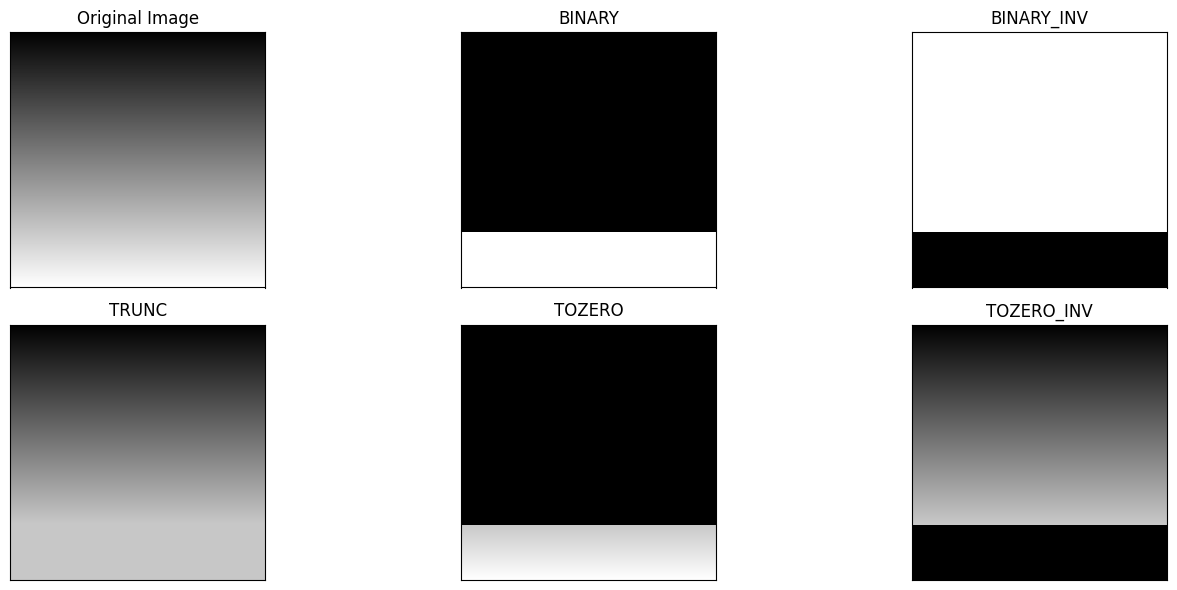

4.


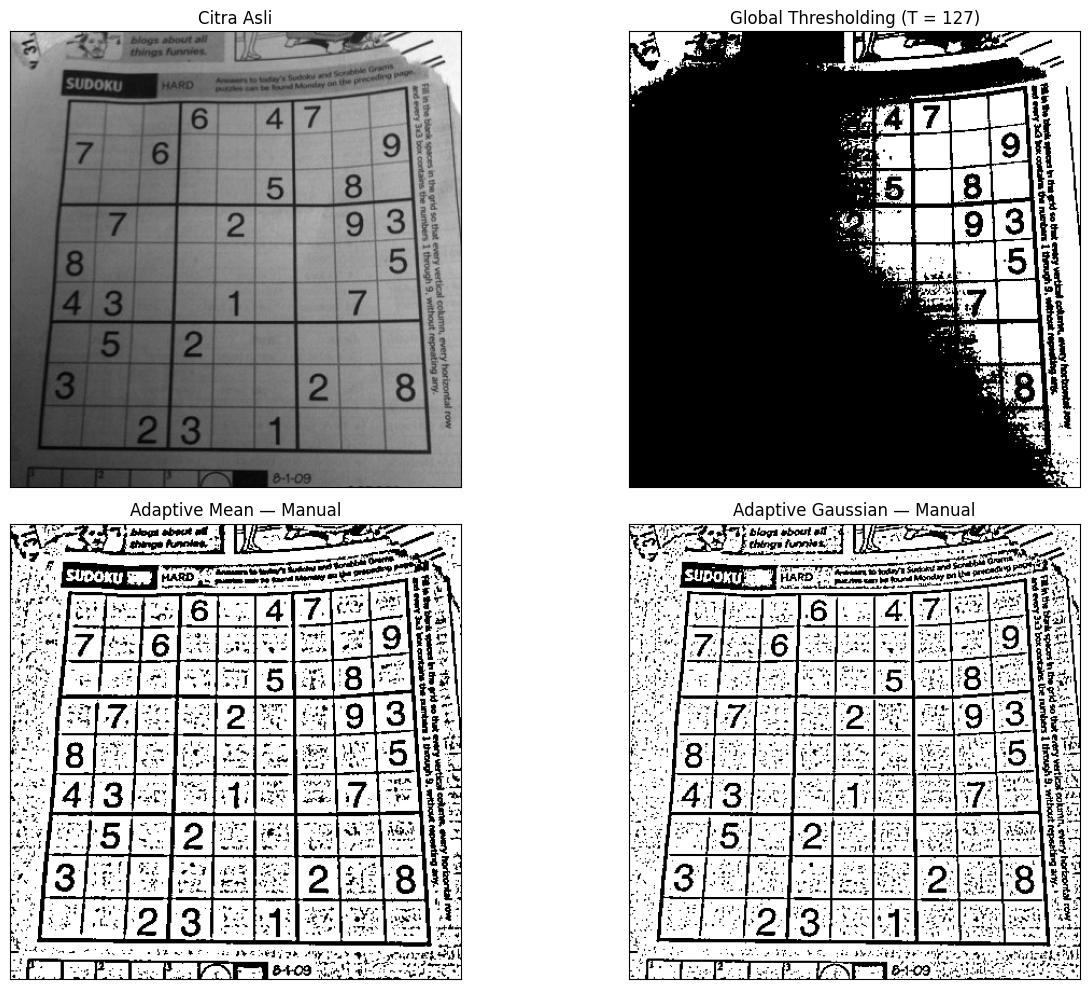

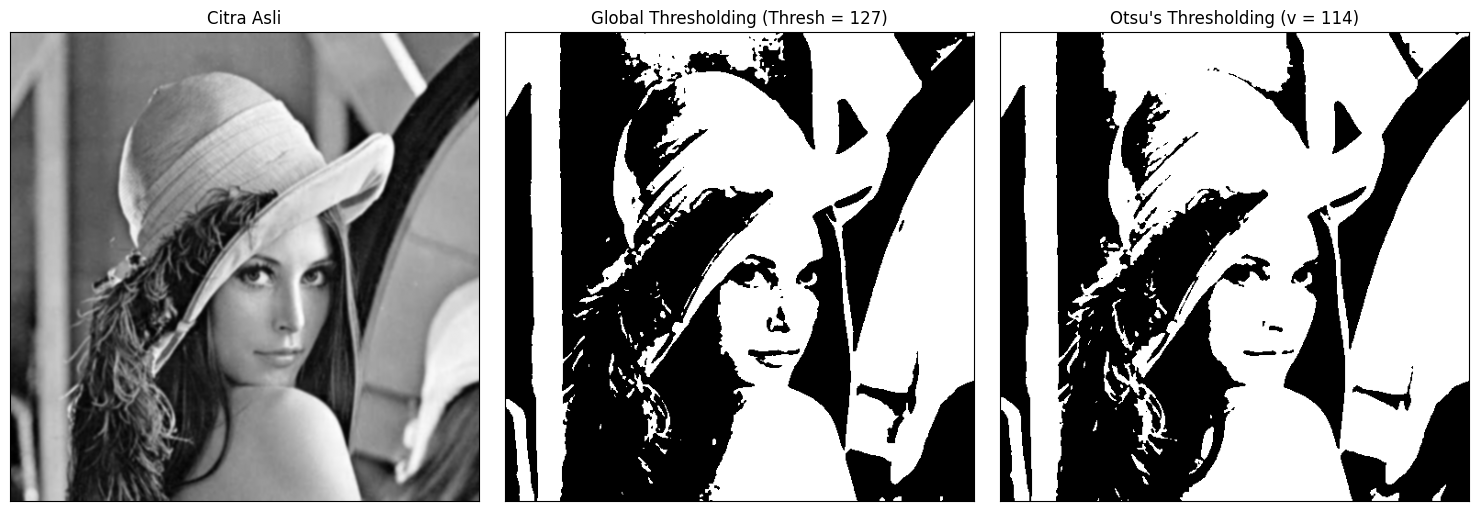

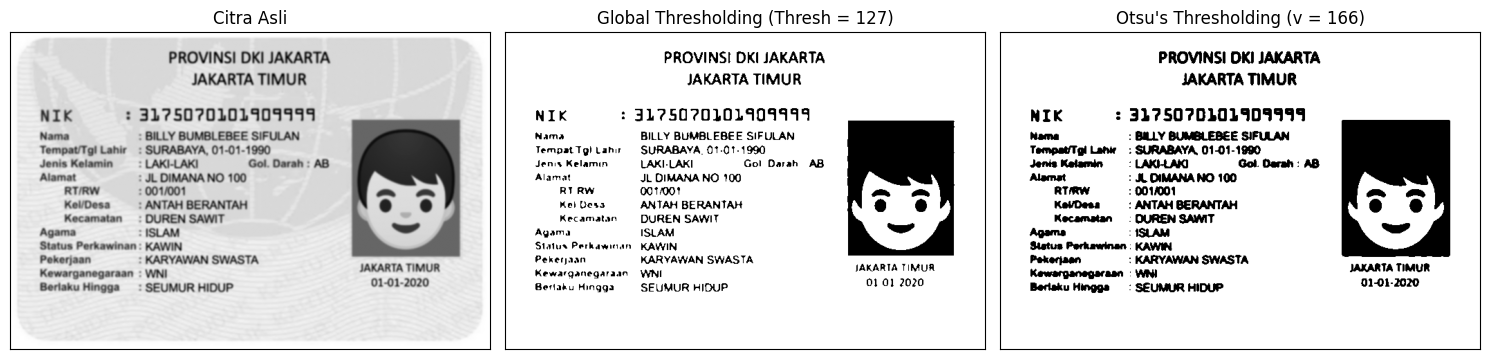

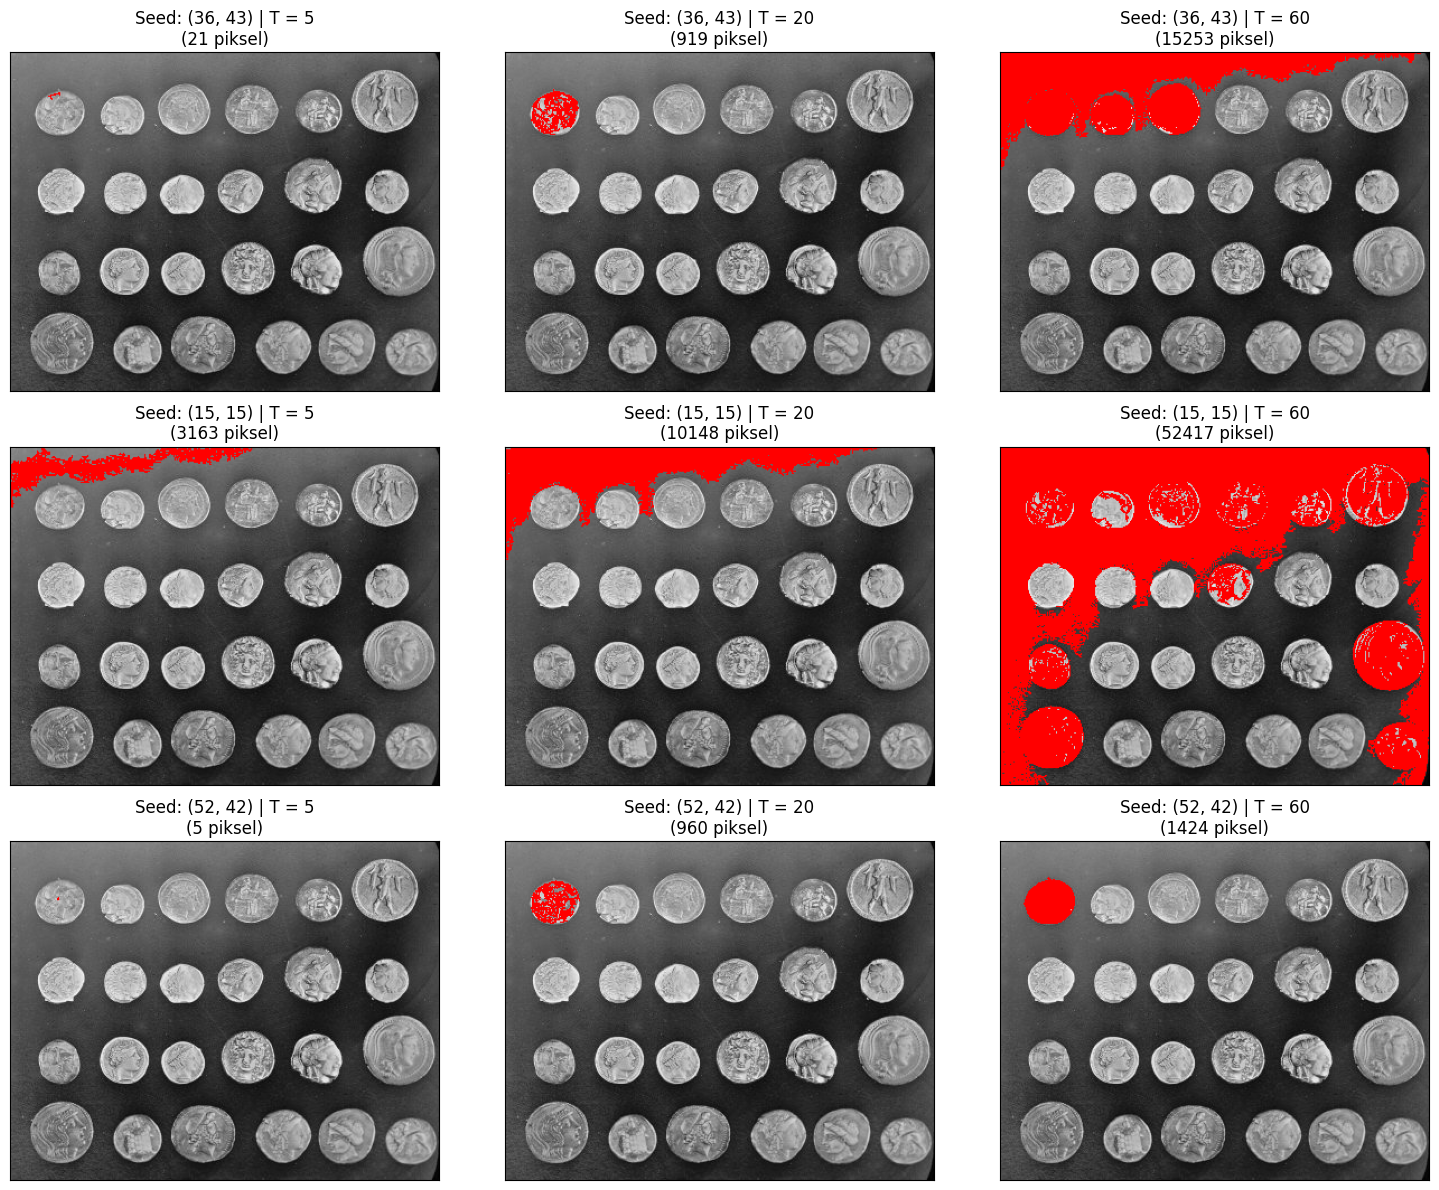

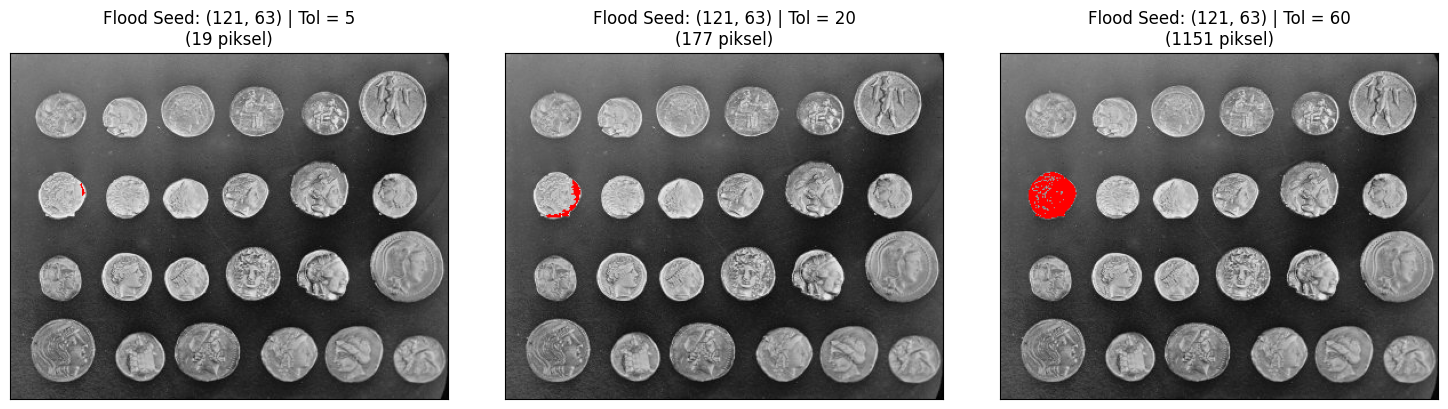

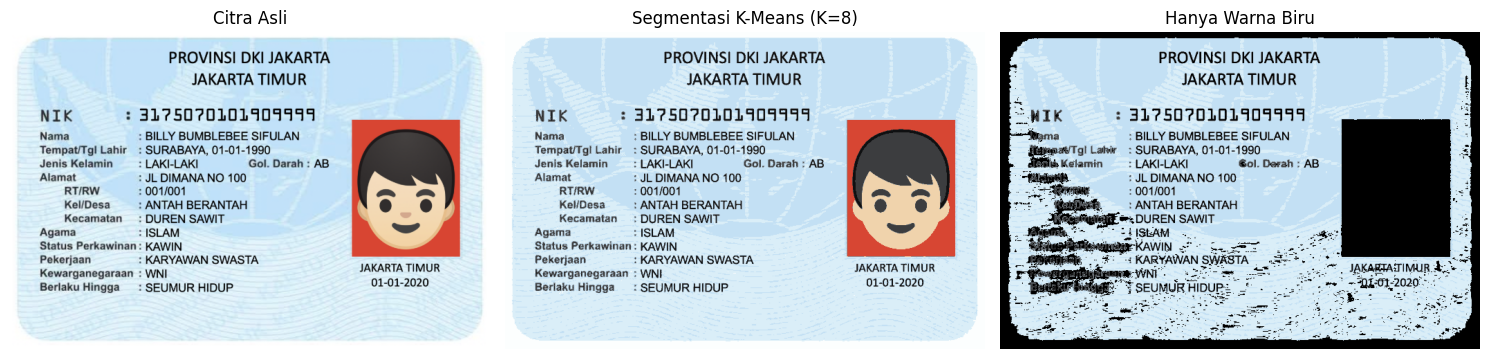

In [12]:
from google.colab import drive
drive.mount('/content/drive')

#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

#3
print("3.")

# 1. Load Citra Gradient
filename = '/content/drive/MyDrive/PCVK/Images/244107020141/gradient.png'
img = cv.imread(filename, 0) # Read as Grayscale

thresh = 200
maxval = 255

# 2. Implementasi Manual Global Thresholding
binary = np.where(img > thresh, maxval, 0).astype(np.uint8)
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)
tozero = np.where(img > thresh, img, 0).astype(np.uint8)
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# 3. Plot Hasil
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

#4
print("4.")

# 1. Load Citra Sudoku
filename_sudoku = '/content/drive/MyDrive/PCVK/Images/244107020141/sudoku-original.jpg'
img_sudoku = cv.imread(filename_sudoku, 0)

# 2. Global Threshold Manual (T = 127)
global_thresh = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

# 3. Fungsi Filter/Konvolusi Manual
def manual_pad(image, pad_size):
    return np.pad(image, pad_size, mode='reflect')

# Kernel Mean Manual (11 x 11)
def adaptive_mean_manual(img, window_size=11, C=2):
    pad = window_size // 2
    padded_img = manual_pad(img, pad)
    h, w = img.shape
    mean_img = np.zeros((h, w), dtype=np.float32)

    # Integral Image / Sliding Window Sum
    for i in range(h):
        for j in range(w):
            window = padded_img[i:i+window_size, j:j+window_size]
            mean_img[i, j] = np.mean(window)

    T = mean_img - C
    out = np.where(img > T, 255, 0).astype(np.uint8)
    return out

# Kernel Gaussian Manual (11 x 11, sigma = 2)
def create_gaussian_kernel(window_size=11, sigma=2):
    k = window_size // 2
    x, y = np.mgrid[-k:k+1, -k:k+1]
    g = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return g / g.sum()

def adaptive_gaussian_manual(img, window_size=11, C=2, sigma=2):
    pad = window_size // 2
    padded_img = manual_pad(img, pad)
    kernel = create_gaussian_kernel(window_size, sigma)
    h, w = img.shape
    gauss_img = np.zeros((h, w), dtype=np.float32)

    for i in range(h):
        for j in range(w):
            window = padded_img[i:i+window_size, j:j+window_size]
            gauss_img[i, j] = np.sum(window * kernel)

    T = gauss_img - C
    out = np.where(img > T, 255, 0).astype(np.uint8)
    return out

# 4. Jalankan Fungsi Manual
adaptive_mean = adaptive_mean_manual(img_sudoku, window_size=11, C=2)
adaptive_gauss = adaptive_gaussian_manual(img_sudoku, window_size=11, C=2, sigma=2)

# 5. Visualisasi Hasil
titles_sudoku = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images_sudoku = [img_sudoku, global_thresh, adaptive_mean, adaptive_gauss]

plt.figure(figsize=(14, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images_sudoku[i], cmap='gray')
    plt.title(titles_sudoku[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

#5
print("5.")

# 1. Definisi Algoritma Otsu Manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        # Between Class Variance
        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

# 2. Pengujian pada Citra Lena (Low Contrast)
filename_lena = '/content/drive/MyDrive/PCVK/Images/244107020141/lena.jpg'
img_lena = cv.imread(filename_lena, 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)

thresh_global = 127
_, th1_lena = cv.threshold(blur_lena, thresh_global, 255, cv.THRESH_BINARY)
otsu_biner_lena, otsu_thresh_lena = otsu(blur_lena)

# Plot Hasil Lena
titles_lena = ['Citra Asli', f'Global Thresholding (Thresh = {thresh_global})', f"Otsu's Thresholding (v = {otsu_thresh_lena})"]
citra_lena = [blur_lena, th1_lena, otsu_biner_lena]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_lena[i], cmap='gray')
    plt.title(titles_lena[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# 3. Pengujian pada Citra KTP
filename_ktp = '/content/drive/MyDrive/PCVK/Images/244107020141/ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

_, th1_ktp = cv.threshold(blur_ktp, thresh_global, 255, cv.THRESH_BINARY)
otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)

# Plot Hasil KTP
titles_ktp = ['Citra Asli', f'Global Thresholding (Thresh = {thresh_global})', f"Otsu's Thresholding (v = {otsu_thresh_ktp})"]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], cmap='gray')
    plt.title(titles_ktp[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

#6
print("6.")

# A. Region Growing Manual dengan 3 Seed dan 3 Toleransi
img_coins = data.coins() # Grayscale (303 x 384)

# Definisi 3 Seed: [Di dalam koin, Di latar belakang, Di tepi koin]
seeds = [
    (36, 43),   # Seed 1: Dalam koin
    (15, 15),   # Seed 2: Latar belakang
    (52, 42)    # Seed 3: Tepi koin
]

tolerances = [5, 20, 60]

def manual_region_growing(img, seed, T):
    h, w = img.shape
    visited = np.zeros((h, w), dtype=bool)
    region_mask = np.zeros((h, w), dtype=bool)

    seed_val = img[seed[0], seed[1]]
    queue = deque([seed])
    visited[seed[0], seed[1]] = True

    # 4-Connectivity
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while queue:
        r, c = queue.popleft()
        region_mask[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
                if abs(float(img[nr, nc]) - float(seed_val)) <= T:
                    visited[nr, nc] = True
                    queue.append((nr, nc))

    return region_mask

# Plot Grid 3 x 3 (Seed x Tolerance)
plt.figure(figsize=(15, 12))
idx = 1
for s_idx, seed in enumerate(seeds):
    for T in tolerances:
        mask = manual_region_growing(img_coins, seed, T)
        pixel_count = np.sum(mask)

        # Overlay warna merah pada region hasil segmentasi
        rgb_display = cv.cvtColor(img_coins, cv.COLOR_GRAY2RGB)
        rgb_display[mask] = [255, 0, 0]

        plt.subplot(3, 3, idx)
        plt.imshow(rgb_display)
        plt.title(f"Seed: {seed} | T = {T}\n({pixel_count} piksel)")
        plt.xticks([]), plt.yticks([])
        idx += 1

plt.tight_layout()
plt.show()

# B. Menggunakan skimage.segmentation.flood()
seed_b = (121, 63)
plt.figure(figsize=(15, 4))

for i, tol in enumerate(tolerances):
    mask_flood = flood(img_coins, seed_b, tolerance=tol, connectivity=1)
    pixel_count = np.sum(mask_flood)

    rgb_flood = cv.cvtColor(img_coins, cv.COLOR_GRAY2RGB)
    rgb_flood[mask_flood] = [255, 0, 0]

    plt.subplot(1, 3, i + 1)
    plt.imshow(rgb_flood)
    plt.title(f"Flood Seed: {seed_b} | Tol = {tol}\n({pixel_count} piksel)")
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

#7
print("7.")

# 1. Baca Citra KTP dan Konversi ke RGB & HSV
filename_ktp_color = '/content/drive/MyDrive/PCVK/Images/244107020141/ktp_fulan.jpg'
img_ktp_bgr = cv.imread(filename_ktp_color)
img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)
img_ktp_hsv = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2HSV)

# 2. Reshape & Terapkan K-Means Clustering (K = 8)
Z = img_ktp_rgb.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented_data = centers[labels.flatten()]
segmented_img = segmented_data.reshape(img_ktp_rgb.shape)

# 3. Filter Isolasi Warna Biru Menggunakan HSV
# Rentang HSV warna biru muda/kebiruan KTP
H = img_ktp_hsv[:, :, 0]
S = img_ktp_hsv[:, :, 1]
V = img_ktp_hsv[:, :, 2]

# Masking Sesuai Petunjuk Modul: (H >= 85 & H <= 130) & (S >= 25) & (V >= 40)
blue_mask = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Tampilkan Hanya Warna Biru (Area Luar Mask Diberi Warna Hitam)
only_blue_img = segmented_img.copy()
only_blue_img[~blue_mask] = [0, 0, 0]

# 4. Visualisasi Hasil
titles_kmeans = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images_kmeans = [img_ktp_rgb, segmented_img, only_blue_img]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images_kmeans[i])
    plt.title(titles_kmeans[i])
    plt.axis('off')
plt.tight_layout()
plt.show()